# EcoSort Waste Management Assistant
# Module 8 Summative Lab

## Overview

You are a data scientist at "EcoSort," a technology company that specializes in developing AI solutions for waste management. EcoSort has partnered with Metro City's waste management department to develop an intelligent waste management assistant that can help residents properly dispose of waste items so less time is spent sorting material at facilities.

This assistant needs to:

1. Identify waste materials from images uploaded by residents (CNN)
2. Classify waste items based on text descriptions provided by residents (RNN/Transformer)
3. Generate specific recycling instructions based on identified waste type and city policies (Generative Transformer with RAG)

Your task is to build this integrated system using the RealWaste dataset along with generated text data that simulates real-world waste management operations.

## Part 1: Dataset Exploration and Preparation

In this section, you will explore and prepare the datasets for your models.

### 1.1 Load and Explore the RealWaste Dataset

In [1]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers
import torch
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.utils.class_weight import compute_class_weight
import os
import random
import json
from PIL import Image

# Set random seeds for reproducibility
np.random.seed(42)
tf.random.set_seed(42)
random.seed(42)

In [11]:
;;# TODO: Load and explore the RealWaste dataset
# - Dataset structure
# - Distribution of waste categories
# - Image characteristics (resolution, quality, background)

# Set the dataset path
data_dir = (
    Path.home()
    / "Downloads"
    / "realwaste"
    / "realwaste-main"
    / "RealWaste"
)

# Check that the dataset exists
if not data_dir.exists():
    raise FileNotFoundError(f"Dataset not found at: {data_dir}")

# Identify waste categories
class_names = sorted([
    folder.name
    for folder in data_dir.iterdir()
    if folder.is_dir()
])

# Find image files in each category
image_extensions = {".jpg", ".jpeg", ".png", ".bmp"}

category_images = {
    category: [
        file for file in (data_dir / category).rglob("*")
        if file.is_file() and file.suffix.lower() in image_extensions
    ]
    for category in class_names
}

# Display basic dataset information
print("Dataset location:", data_dir)
print("Number of categories:", len(class_names))
print("Categories:", class_names)
print("Total images:", sum(len(images) for images in category_images.values()))

Dataset location: C:\Users\user\Downloads\realwaste\realwaste-main\RealWaste
Number of categories: 9
Categories: ['Cardboard', 'Food Organics', 'Glass', 'Metal', 'Miscellaneous Trash', 'Paper', 'Plastic', 'Textile Trash', 'Vegetation']
Total images: 4752


Cardboard: 461 images
Food Organics: 411 images
Glass: 420 images
Metal: 790 images
Miscellaneous Trash: 495 images
Paper: 500 images
Plastic: 921 images
Textile Trash: 318 images
Vegetation: 436 images


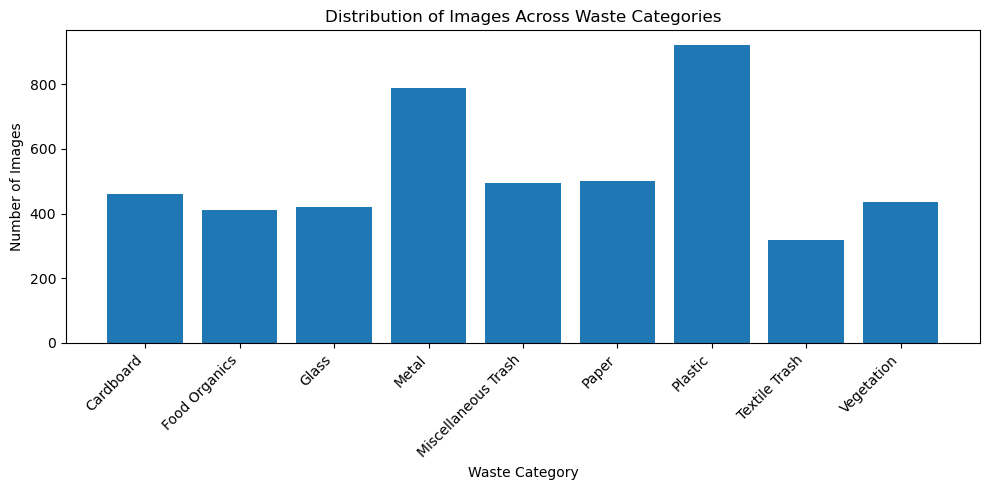

In [9]:
# number of images in each category
category_counts = {
    category: len(images)
    for category, images in category_images.items()
}

for category, count in category_counts.items():
    print(f"{category}: {count} images")

# distribution of images plot
plt.figure(figsize=(10, 5))
plt.bar(category_counts.keys(), category_counts.values())
plt.title("Distribution of Images Across Waste Categories")
plt.xlabel("Waste Category")
plt.ylabel("Number of Images")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [13]:
# image dimensions and size
from collections import Counter

image_sizes = Counter()
image_formats = Counter()
image_modes = Counter()
corrupted_images = []

for category, images in category_images.items():
    for image_path in images:
        try:
            with Image.open(image_path) as img:
                image_sizes[img.size] += 1
                image_formats[img.format] += 1
                image_modes[img.mode] += 1
        except Exception as e:
            corrupted_images.append(str(image_path))

print("Most common image dimensions:")
print(image_sizes.most_common(10))

print("\nImage formats:")
print(image_formats)

print("\nImage color modes:")
print(image_modes)

print("\nImages that could not be opened:", len(corrupted_images))

Most common image dimensions:
[((524, 524), 4752)]

Image formats:
Counter({'JPEG': 4752})

Image color modes:
Counter({'RGB': 4752})

Images that could not be opened: 0


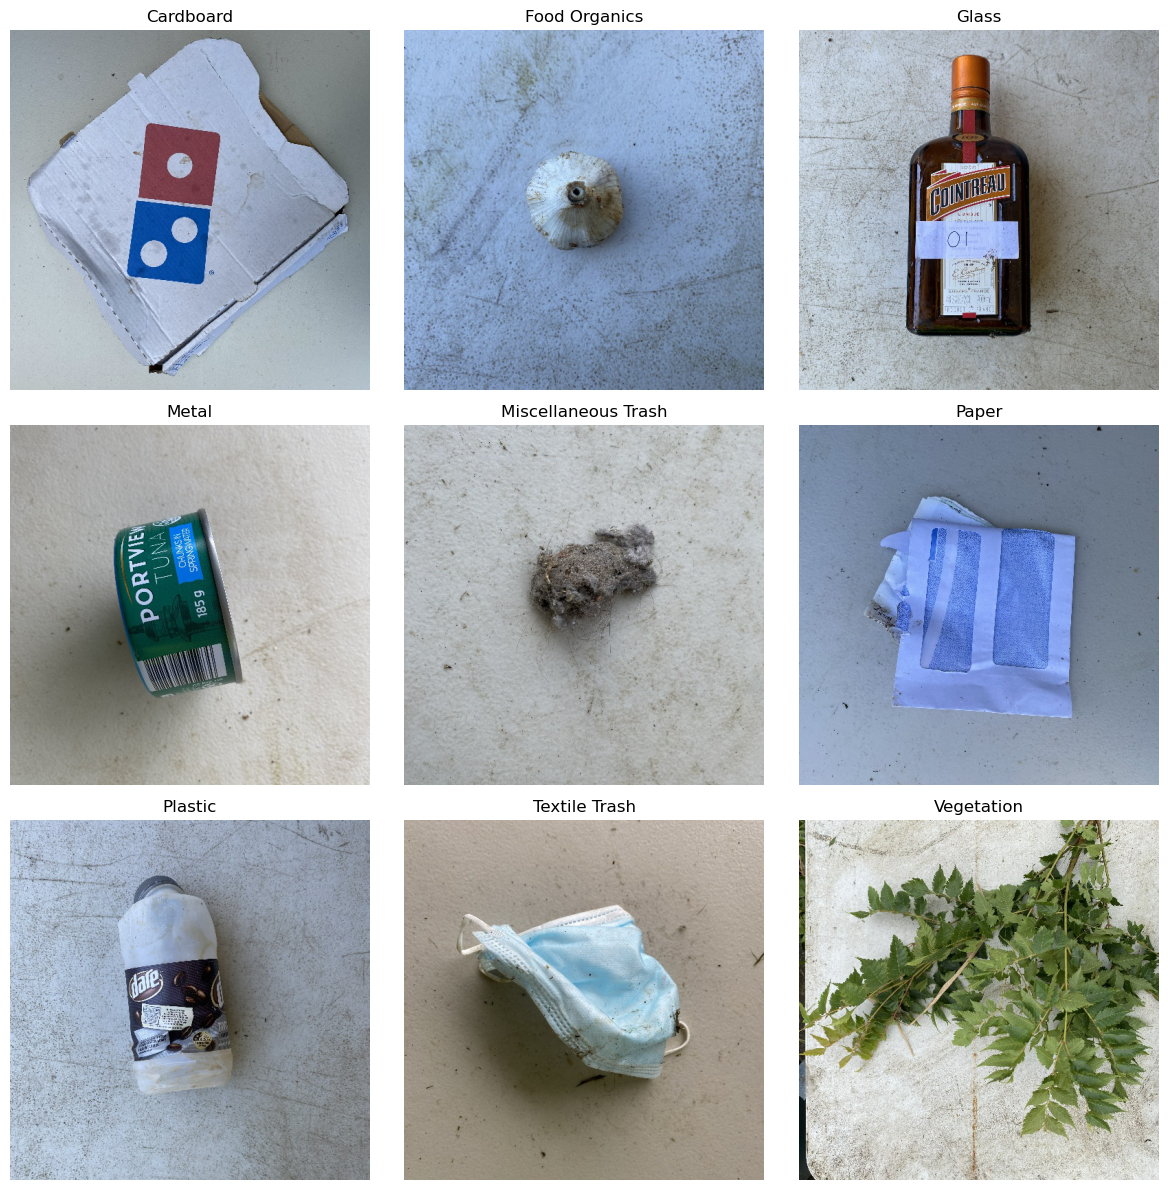

In [12]:
# view random image
fig, axes = plt.subplots(3, 3, figsize=(12, 12))
axes = axes.flatten()

for ax, category in zip(axes, class_names):
    image_path = random.choice(category_images[category])

    with Image.open(image_path) as img:
        ax.imshow(img.convert("RGB"))

    ax.set_title(category)
    ax.axis("off")

plt.tight_layout()
plt.show()

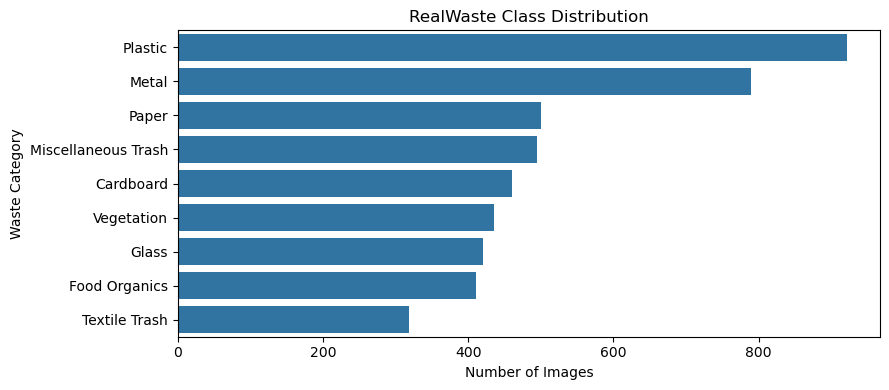

Total images: 4752
Number of categories: 9
Imbalance ratio (largest/smallest class): 2.90x

Images per category:
label
Plastic                921
Metal                  790
Paper                  500
Miscellaneous Trash    495
Cardboard              461
Vegetation             436
Glass                  420
Food Organics          411
Textile Trash          318
Name: count, dtype: int64


In [16]:

# Class distribution
category_counts = {
    category: len(images)
    for category, images in category_images.items()
}

img_df = pd.DataFrame([
    {"path": str(image_path), "label": category}
    for category, images in category_images.items()
    for image_path in images
])

plt.figure(figsize=(9, 4))
sns.countplot(
    data=img_df,
    y="label",
    order=img_df["label"].value_counts().index
)
plt.title("RealWaste Class Distribution")
plt.xlabel("Number of Images")
plt.ylabel("Waste Category")
plt.tight_layout()
plt.show()

vc = img_df["label"].value_counts()
print(f"Total images: {len(img_df)}")
print(f"Number of categories: {len(vc)}")
print(
    "Imbalance ratio (largest/smallest class): "
    f"{vc.max() / vc.min():.2f}x"
)

print("\nImages per category:")
print(vc)


In [17]:

# Image characteristics
SEED = 42

sample_paths = [
    image_path
    for images in category_images.values()
    for image_path in images
]

sample_df = pd.DataFrame({"path": sample_paths}).sample(
    n=min(300, len(sample_paths)),
    random_state=SEED
)

stats = []
unreadable_images = []

for image_path in sample_df["path"]:
    try:
        with Image.open(image_path) as img:
            grayscale = np.asarray(img.convert("L"), dtype=np.float32)

            stats.append({
                "width": img.width,
                "height": img.height,
                "mode": img.mode,
                "brightness": grayscale.mean(),
                "contrast": grayscale.std()
            })
    except (OSError, ValueError):
        unreadable_images.append(str(image_path))

stats = pd.DataFrame(stats)

print("Successfully analysed images:", len(stats))
print("Unreadable images in sample:", len(unreadable_images))

print("\nResolutions in sample:")
print(stats.groupby(["width", "height"]).size().to_dict())

print("\nColour modes in sample:")
print(stats["mode"].value_counts().to_dict())

print("\nBrightness and contrast summary:")
print(stats[["brightness", "contrast"]].describe().round(1))


Successfully analysed images: 300
Unreadable images in sample: 0

Resolutions in sample:
{(524, 524): 300}

Colour modes in sample:
{'RGB': 300}

Brightness and contrast summary:
       brightness  contrast
count       300.0     300.0
mean        156.4      41.6
std          10.0      12.5
min         114.9      15.9
25%         150.8      33.4
50%         156.1      40.0
75%         162.6      48.3
max         180.4      76.5


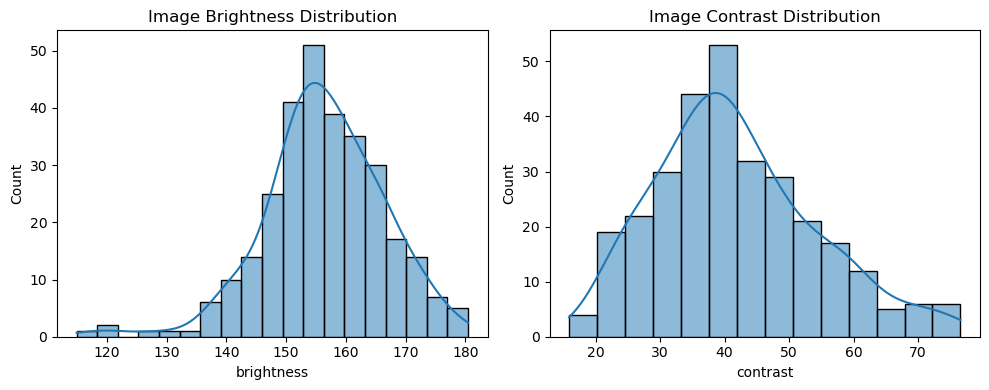

In [18]:
# brightness and contrast plot
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

sns.histplot(stats["brightness"], kde=True, ax=axes[0])
axes[0].set_title("Image Brightness Distribution")

sns.histplot(stats["contrast"], kde=True, ax=axes[1])
axes[1].set_title("Image Contrast Distribution")

plt.tight_layout()
plt.show()

### 1.2 Explore Text Datasets

In [20]:
# TODO: Load and explore the waste description text data
# - Load waste_descriptions.csv
# - Analyze vocabulary and structure
# - Understand the distribution of categories


# Load waste description text data
text_df = pd.read_csv("waste_descriptions.csv")

print(text_df.shape)

print("\nColumn names:")
print(text_df.columns.tolist())

(5000, 5)

Column names:
['description', 'category', 'disposal_instruction', 'common_confusion', 'material_composition']


In [ ]:
# TODO: Load and explore the waste policy documents
# - Load waste_policy_documents.csv
# - Understand document organization and language

# Your code here

### 1.3 Create Data Pipelines

In [ ]:
# Run this code to setup the images properly into train, validation, and test sets
# Set your data directory path - update this with your actual path
import pathlib
data_dir = pathlib.Path('RealWaste')

# Parameters
BATCH_SIZE = 32
IMG_HEIGHT = 224
IMG_WIDTH = 224

# Calculate the total number of classes automatically from the directory structure
num_classes = len([item for item in data_dir.glob('*') if item.is_dir()])
print(f"Number of classes: {num_classes}")

# List all class folders
class_names = sorted([item.name for item in data_dir.glob('*') if item.is_dir()])
print(f"Class names: {class_names}")

# Count all images
image_count = len(list(data_dir.glob('*/*.jpg'))) + len(list(data_dir.glob('*/*.png')))
print(f"Total images found: {image_count}")

# Create a dataset using tf.keras.utils.image_dataset_from_directory
# This will automatically split the data into training and validation sets
train_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,  # 20% for validation
    subset="training",
    seed=42,
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    label_mode='categorical',  # For one-hot encoded labels
    shuffle=True
)

validation_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,  # 20% for validation
    subset="validation",
    seed=42,
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    label_mode='categorical',  # For one-hot encoded labels
    shuffle=True
)

# Create a separate test dataset by taking part of the validation set
# First, let's get the number of batches in the validation set
val_batches = tf.data.experimental.cardinality(validation_ds)
test_dataset = validation_ds.take(val_batches // 2)
validation_ds = validation_ds.skip(val_batches // 2)

print(f"Number of training batches: {tf.data.experimental.cardinality(train_ds)}")
print(f"Number of validation batches: {tf.data.experimental.cardinality(validation_ds)}")
print(f"Number of test batches: {tf.data.experimental.cardinality(test_dataset)}")

# Configure dataset for performance
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.cache().prefetch(buffer_size=AUTOTUNE)
validation_ds = validation_ds.cache().prefetch(buffer_size=AUTOTUNE)
test_dataset = test_dataset.cache().prefetch(buffer_size=AUTOTUNE)

In [ ]:
# TODO: Create a text preprocessing pipeline
# - Tokenization
# - Text cleaning
# - Split data into train and test
# - Create embeddings/features

# Your code here

In [ ]:
# TODO: Prepare documents for RAG
# - Document preprocessing
# - Create embeddings for retrieval

# Your code here

## Part 2: Waste Material Classification with CNN

In this section, you will build a CNN model to classify waste materials from images.

### 2.1 Preprocess Images

In [ ]:
# TODO: Implement image preprocessing
# - Apply the preprocessing pipeline created earlier

# Your code here

### 2.2 Implement CNN Model with Transfer Learning

In [ ]:
# TODO: Select an appropriate base model and implement transfer learning
# - Choose from MobileNet, EfficientNet, etc.
# - Add custom classification layers for the 9 waste categories
# - Configure loss function and metrics

# Your code here

### 2.3 Train and Evaluate the Model

In [ ]:
# TODO: Train the CNN model
# - Use appropriate batch size and epochs
# - Implement regularization to prevent overfitting
# - Monitor training and validation metrics

# Your code here

In [ ]:
# TODO: Evaluate model performance
# - Calculate accuracy on test set
# - Generate confusion matrix
# - Analyze error patterns

# Your code here

### 2.4 Fine-tune the Model

In [ ]:
# TODO: Tune model parameters to improve performance
# - Adjust learning rate
# - Add regularization, dropout
# - Modify architecture if needed

# Your code here

## Part 3: Waste Description Classification

In this section, you will build a text classification model to categorize waste based on descriptions.

### 3.1 Preprocess Text Data

In [ ]:
# TODO: Implement text preprocessing
# - Apply the text preprocessing pipeline created earlier

# Your code here

### 3.2 Implement Text Classification Model

In [ ]:
# TODO: Choose and implement a text classification model
# Option A: Traditional ML model (Naive Bayes, Random Forest, etc.)
# Option B: Fine-tune a transformer-based model (BERT, DistilBERT, etc.)

# Your code here

### 3.3 Train and Evaluate the Model

In [ ]:
# TODO: Train the text classification model
# - Use appropriate training parameters
# - Monitor training progress

# Your code here

In [ ]:
# TODO: Evaluate model performance
# - Calculate accuracy on test set
# - Generate confusion matrix
# - Analyze error patterns

# Your code here

### 3.4 Create Classification Function

In [ ]:
# TODO: Create a function that takes a text description and returns the predicted waste category

def classify_waste_description(description):
    """
    Classifies a waste description into an appropriate category.

    Args:
        description (str): Text description of waste item

    Returns:
        str: Predicted waste category
    """
    # Your code here
    pass

## Part 4: Recycling Instruction Generation with RAG

In this section, you will implement a Retrieval-Augmented Generation (RAG) system to generate recycling instructions.

### 4.1 Preprocess Documents for Retrieval

In [ ]:
# TODO: Prepare documents for retrieval
# - Process policy documents and disposal instructions
# - Create embeddings for efficient retrieval

# Your code here

### 4.2 Implement RAG-based System

In [ ]:
# TODO: Select a pre-trained language model and implement RAG
# - Choose an appropriate language model
# - Create a retrieval mechanism

# Your code here

### 4.3 Adjust and Evaluate the System

In [ ]:
# TODO: Train the RAG-based system
# - Adjust sampling methods/parameters

# Your code here

In [ ]:
# TODO: Evaluate the quality of generated instructions
# - Test with various waste categories
# - Assess relevance and accuracy

# Your code here

### 4.4 Create Instruction Generation Function

In [ ]:
# TODO: Create a function that takes a waste category and generates recycling instructions

def generate_recycling_instructions(waste_category):
    """
    Generates detailed recycling instructions for a given waste category.

    Args:
        waste_category (str): Waste category

    Returns:
        str: Detailed recycling instructions
        list: Relevant policy documents
    """
    # Your code here
    pass

## Part 5: Integrated Waste Management Assistant

In this section, you will integrate all three models into a unified waste management assistant.

### 5.1 Design Integration Architecture

In [ ]:
# TODO: Design an architecture that integrates all three models
# - Create interfaces between components
# - Handle input/output flow

# Your code here

### 5.2 Implement Integrated Assistant

In [ ]:
# TODO: Implement the integrated waste management assistant

def waste_management_assistant(input_data, input_type="image"):
    """
    Integrated waste management assistant that processes either images or text descriptions
    and returns waste classification and recycling instructions.

    Args:
        input_data: Either an image file path/array or a text description
        input_type (str): Type of input - "image" or "text"

    Returns:
        dict: Dictionary containing waste category, confidence, and recycling instructions
    """
    # Your code here
    pass

### 5.3 Evaluate the Integrated System

In [ ]:
# TODO: Evaluate the integrated system on test cases
# - Test with images from test dataset
# - Test with text descriptions from test dataset
# - Assess overall performance

# Your code here

## Submission Guidelines

1. Make sure all code cells are properly commented and annotated
2. Ensure that all functions are implemented and working correctly
3. Verify that all evaluation metrics are calculated and analyzed
4. Double-check that the integrated system works as expected
5. Submit your completed and annotated Jupyter notebook file

Remember to demonstrate your understanding of the underlying concepts and provide justification for your design decisions throughout the notebook.